<a href="https://colab.research.google.com/github/KhethiweDlamini/KhethiweDlamini/blob/main/Practicals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import csv
from itertools import islice
import random as rand
import matplotlib.pyplot as plt
import numpy as np
import time

## Practical 1

In [ ]:
path = '/content/drive/MyDrive/Colab Notebooks/ml_at_scale/ml-32m/ratings.csv'

# indexing map
user_to_index = {}
index_to_user = []
movie_to_index = {}
index_to_movie = []

data_by_user = []
data_by_movie = []

with open(path, 'r') as f:
  reader = csv.reader(f)
  next(reader) # exclude the row with headers
  for row in reader:
    user_id = int(row[0])
    movie_id = int(row[1])
    rating = float(row[2])

    if user_id not in user_to_index:
      m = len(index_to_user)
      user_to_index[user_id] = m
      index_to_user.append(user_id)
      data_by_user.append([])
    else:
      m = user_to_index[user_id]

    if movie_id not in movie_to_index:
      n = len(index_to_movie)
      movie_to_index[movie_id] = n
      index_to_movie.append(movie_id)
      data_by_movie.append([])
    else:
      n = movie_to_index[movie_id]

    data_by_user[m].append((n,rating))
    data_by_movie[n].append((m,rating))

### Plot Distribution for Ratings

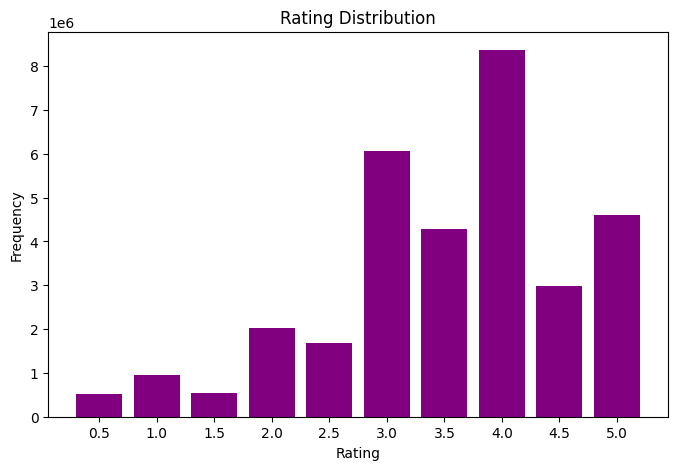

In [ ]:
# Collect all ratings
all_ratings = []
for rating_pairs in data_by_user:
  for rating in rating_pairs:
    all_ratings.append(rating[1])

all_ratings = np.array(all_ratings)

# Get frequencies
unique_ratings, counts = np.unique(all_ratings, return_counts = True)

# Plot of the Distributionfor movie in rating_pairs: of Ratings
plt.figure(figsize=(8,5))
plt.bar(unique_ratings, counts, width=0.4, color='purple')
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.title("Rating Distribution")
plt.xticks(unique_ratings)
plt.savefig('ratings_dist.svg')
plt.show()

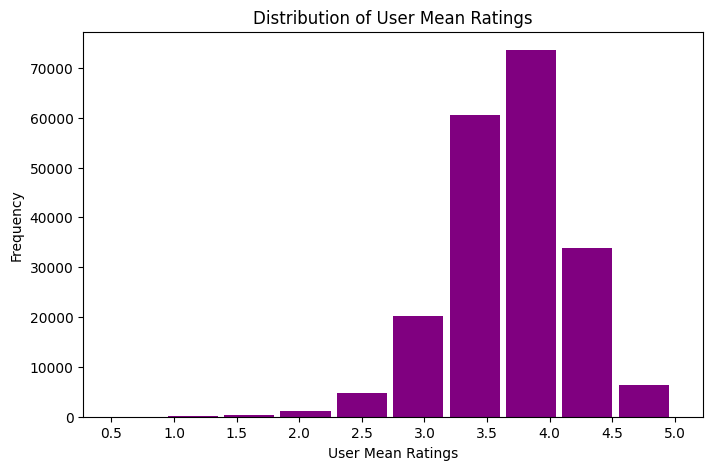

In [ ]:
user_mean_ratings = []

for user in data_by_user:
  total = 0
  for rating in user:
    total += rating[1]

  user_mean = total/len(user)
  user_mean_ratings.append(user_mean)

  # Plot Users Mean Ratings
plt.figure(figsize=(8,5))
plt.hist(user_mean_ratings, bins = 10, width = 0.4, color = 'purple')

plt.xlabel("User Mean Ratings")
plt.ylabel("Frequency")
plt.title("Distribution of User Mean Ratings")
plt.xticks(unique_ratings)
plt.savefig('user_mean_ratings.svg')
plt.show()


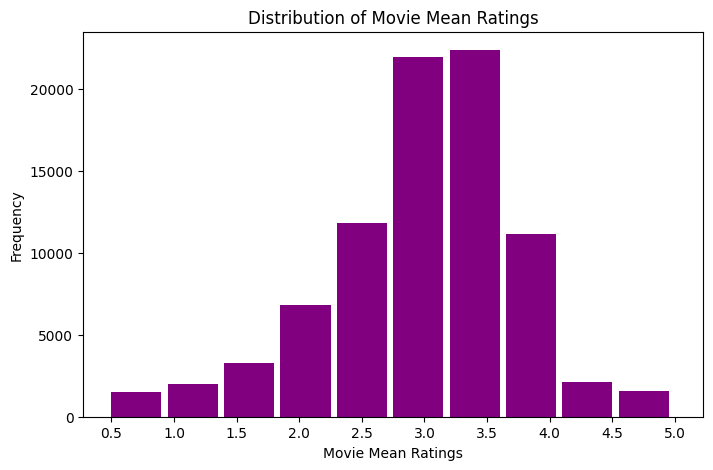

In [ ]:
# Plot Users Mean Ratings
movie_mean_ratings = []

for movie in data_by_movie:
  total = 0
  for rating in movie:
    total += rating[1]

  movie_mean = total/len(movie)
  movie_mean_ratings.append(movie_mean)

plt.figure(figsize=(8,5))
plt.hist(movie_mean_ratings, bins = 10, width = 0.4, color = 'purple')

plt.xlabel("Movie Mean Ratings")
plt.ylabel("Frequency")
plt.title("Distribution of Movie Mean Ratings")
plt.savefig('movie_mean_ratings.svg')
plt.xticks(unique_ratings)
plt.show()

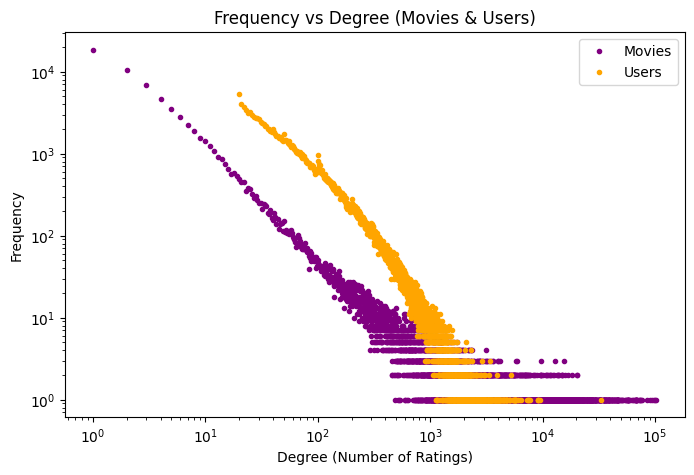

In [ ]:
# Plotting Degree vs Frequency for users and and Movies
# Degree = number of ratings per movie/user.
# Frequency = how many movies/users have that degree.
user_degrees = []
for user in data_by_user:
  u_degree = len(user)
  user_degrees.append(u_degree)

user_deg_freq, user_counts = np.unique(user_degrees, return_counts= True)

movie_degrees = []
for movie in data_by_movie:
  m_degree = len(movie)
  movie_degrees.append(m_degree)

movie_deg_freq, movie_counts = np.unique(movie_degrees, return_counts= True)

# Plot
plt.figure(figsize=(8,5))
plt.loglog(movie_deg_freq, movie_counts, marker='.', linestyle='none', color='purple', label='Movies')
plt.loglog(user_deg_freq, user_counts, marker='.', linestyle='none', color='orange', label='Users')
plt.xlabel("Degree (Number of Ratings)")
plt.ylabel("Frequency")
plt.title("Frequency vs Degree (Movies & Users)")
plt.legend()
plt.savefig('frequency_vs_degree.svg')
plt.show()


Are there power laws in the data?

For both the users and the movies frequency is high for lower degrees and low for high degrees so ther are power laws for both users and movies. In the case of users, this means there are few users with many movie ratings, while the vast majority of users gave fewer ratings, but since each user gave at least 20 ratings the power law for users is skewed.


In [ ]:
path = '/content/drive/MyDrive/Colab Notebooks/ml_at_scale/ml-32m/ratings.csv'

# indexing map
user_to_index = {}
index_to_user = []
movie_to_index = {}
index_to_movie = []

data_by_user = []
data_by_movie = []

data_by_user_train = []
data_by_user_test = []
data_by_movie_train = []
data_by_movie_test = []

rand.seed(42)

with open(path, 'r') as f:
  reader = csv.reader(f)
  next(reader) # exclude the row with headers
  for row in islice(reader,100000):
    user_id = int(row[0])
    movie_id = int(row[1])
    rating = float(row[2])

    if user_id not in user_to_index:
      m = len(index_to_user)
      user_to_index[user_id] = m
      index_to_user.append(user_id)
      data_by_user.append([])
      data_by_user_train.append([])
      data_by_user_test.append([])
    else:
      m = user_to_index[user_id]

    if movie_id not in movie_to_index:
      n = len(index_to_movie)
      movie_to_index[movie_id] = n
      index_to_movie.append(movie_id)
      data_by_movie.append([])
      data_by_movie_train.append([])
      data_by_movie_test.append([])
    else:
      n = movie_to_index[movie_id]

    data_by_user[m].append((n,rating))
    data_by_movie[n].append((m,rating))

    # Splitting into train and test sets
    # Set seed
    cutoff = 0.2
    if rand.random() > cutoff:
      data_by_user_train[m].append((n,rating))
      data_by_movie_train[n].append((m,rating))
    else:
      data_by_user_test[m].append((n,rating))
      data_by_movie_test[n].append((m,rating))

  # print(len(data_by_user_train), len(data_by_user_test))
  # print(len(data_by_movie_train), len(data_by_movie_test))

In [ ]:
# Count non-empty elements using list comprehension
user_train_count = sum(1 for user in data_by_user_train if len(user) > 0)
user_test_count = sum(1 for user in data_by_user_test if len(user) > 0)
movie_train_count = sum(1 for user in data_by_movie_train if len(user) > 0)
movie_test_count = sum(1 for user in data_by_movie_test if len(user) > 0)
test_count = sum(1 for item in data_by_user_test if len(item) > 0)

print(f'Length of data_by_user train: {len(data_by_user_train)}')
print(f'Length of data_by_user test: {len(data_by_user_test)}')
print(f'Number of non-zero mappings in training set for data_by_user: {user_train_count}')
print(f'Number of non-zero mappings in test set for data_by_user: {user_test_count}')
print(f'Length of data_by_user train: {len(data_by_movie_train)}')
print(f'Length of data_by_user test: {len(data_by_movie_test)}')
print(f'Number of non-zero mappings in training set for data_by_movie: {movie_train_count}')
print(f'Number of non-zero mappings in test set for data_by_movie: {movie_test_count}')


Length of data_by_user train: 626
Length of data_by_user test: 626
Number of non-zero mappings in training set for data_by_user: 626
Number of non-zero mappings in test set for data_by_user: 626
Length of data_by_user train: 10225
Length of data_by_user test: 10225
Number of non-zero mappings in training set for data_by_movie: 9432
Number of non-zero mappings in test set for data_by_movie: 5219


# Practical 2

### Computing ALS for user + item biases

Iteration 1/10: Train RMSE = 0.8328, Test RMSE = 0.9159, NLL Loss = 276.89
Iteration 2/10: Train RMSE = 0.8207, Test RMSE = 0.9057, NLL Loss = 268.92
Iteration 3/10: Train RMSE = 0.8196, Test RMSE = 0.9050, NLL Loss = 268.19
Iteration 4/10: Train RMSE = 0.8194, Test RMSE = 0.9049, NLL Loss = 268.05
Iteration 5/10: Train RMSE = 0.8193, Test RMSE = 0.9048, NLL Loss = 268.01
Iteration 6/10: Train RMSE = 0.8193, Test RMSE = 0.9048, NLL Loss = 267.98
Iteration 7/10: Train RMSE = 0.8193, Test RMSE = 0.9047, NLL Loss = 267.96
Iteration 8/10: Train RMSE = 0.8192, Test RMSE = 0.9047, NLL Loss = 267.95
Iteration 9/10: Train RMSE = 0.8192, Test RMSE = 0.9047, NLL Loss = 267.94
Iteration 10/10: Train RMSE = 0.8192, Test RMSE = 0.9046, NLL Loss = 267.93


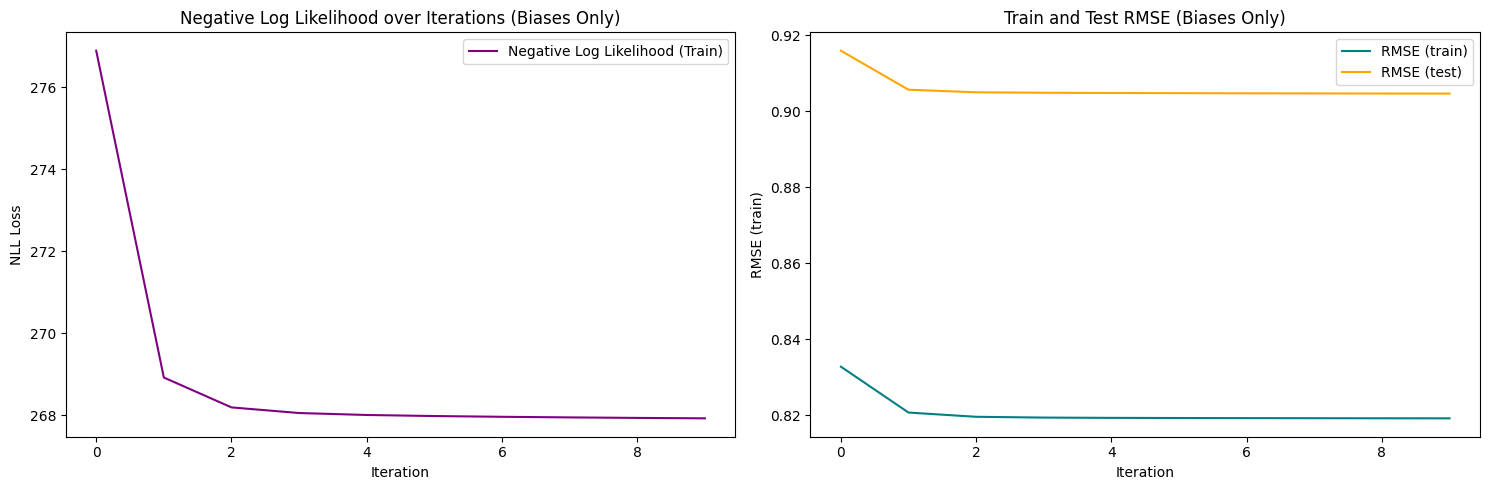

In [ ]:
M = len(data_by_user_train)
N = len(data_by_movie_train)
user_biases = np.zeros((M))
movie_biases = np.zeros ((N))

lambd = 0.01  # update weight factor
gamma = 0.01  # regularisation term for biases
n_iters = 10

train_rmse_history = []
test_rmse_history = []
loss_history = []
neg_ll_history = []

# Calculate the global mean for ratings
mu = 0
num_ratings = 0
for m in range(M):
  for (n,r) in data_by_user_train[m]:
    mu += r
    num_ratings += 1

mu /= num_ratings

for iter in range(n_iters):
  # Update user biases
  for m in range(M):
    bias = 0
    movie_counter = 0
    for (n,r) in data_by_user_train[m]:
      bias += lambd * (r - mu - movie_biases[n])
      movie_counter += 1

    bias = bias / (lambd * movie_counter + gamma)
    user_biases[m] = bias

  # Update movie biases
  for n in range(N):
    bias = 0
    user_counter = 0
    for (m,r) in data_by_movie_train[n]:
      bias += lambd * (r - mu - user_biases[m])
      user_counter += 1

    bias = bias / (lambd * user_counter + gamma)
    movie_biases[n] = bias

  # Training loss & RMSE
  squared_error = 0
  count = 0
  for m in range(M):
    for (n,r) in data_by_user_train[m]:
      pred = mu + user_biases[m] + movie_biases[n]
      squared_error += (r - pred) ** 2
      count += 1

  rmse_train = np.sqrt(squared_error / count)
  train_rmse_history.append(rmse_train)


  # Compute negative log likelihood on training data
  log_likelihood = -(lambd / 2) * squared_error - (gamma / 2)
  neg_ll = -log_likelihood
  neg_ll_history.append(neg_ll)

  # Test RMSE
  squared_error_test = 0
  count_test = 0
  for m in range(M):
    for (n,r) in data_by_user_test[m]:
      pred = mu + user_biases[m] + movie_biases[n]
      squared_error_test += (r - pred) ** 2
      count_test += 1

  rmse_test = np.sqrt(squared_error_test / count_test)
  test_rmse_history.append(rmse_test)

  print(f"Iteration {iter+1}/{n_iters}: "
          f"Train RMSE = {rmse_train:.4f}, Test RMSE = {rmse_test:.4f}, "
          f"NLL Loss = {neg_ll:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Negative Log Likelihood
axes[0].plot(neg_ll_history, color='purple', label='Negative Log Likelihood (Train)')
axes[0].set_title("Negative Log Likelihood over Iterations (Biases Only)")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("NLL Loss")
axes[0].legend()

# Plot 2
axes[1].plot(train_rmse_history, color='teal', label='RMSE (train)')
axes[1].plot(test_rmse_history, color='orange', label='RMSE (test)')
axes[1].set_title("Train and Test RMSE (Biases Only)")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("RMSE (train)")
axes[1].legend()
plt.savefig('NLL_RMSE_biases.svg')

plt.tight_layout()
plt.show()

In [ ]:
print(f'Training RMSE corverges to : {train_rmse_history[-1]:.4f}')
print(f'Test RMSE corverges to : {test_rmse_history[-1]:.4f}')

Training RMSE corverges to : 0.8192
Test RMSE corverges to : 0.9046


# Practical 3

In [ ]:
path = '/content/drive/MyDrive/Colab Notebooks/ml_at_scale/ml-32m/ratings.csv'

# indexing map
user_to_index = {}
index_to_user = []
movie_to_index = {}
index_to_movie = []

data_by_user = []
data_by_movie = []

data_by_user_train = []
data_by_user_test = []
data_by_movie_train = []
data_by_movie_test = []


with open(path, 'r') as f:
  reader = csv.reader(f)
  next(reader) # exclude the row with headers
  for row in islice(reader,100000):
    user_id = int(row[0])
    movie_id = int(row[1])
    rating = float(row[2])

    if user_id not in user_to_index:
      m = len(index_to_user)
      user_to_index[user_id] = m
      index_to_user.append(user_id)
      data_by_user.append([])
      data_by_user_train.append([])
      data_by_user_test.append([])
    else:
      m = user_to_index[user_id]

    if movie_id not in movie_to_index:
      n = len(index_to_movie)
      movie_to_index[movie_id] = n
      index_to_movie.append(movie_id)
      data_by_movie.append([])
      data_by_movie_train.append([])
      data_by_movie_test.append([])
    else:
      n = movie_to_index[movie_id]

    data_by_user[m].append((n,rating))
    data_by_movie[n].append((m,rating))

    # Splitting into train and test sets
    cutoff = 0.2
    if rand.random() > cutoff:
      data_by_user_train[m].append((n,rating))
      data_by_movie_train[n].append((m,rating))
    else:
      data_by_user_test[m].append((n,rating))
      data_by_movie_test[n].append((m,rating))

Iteration 1/10: Train RMSE = 0.8149, Test RMSE = 0.9168, NLL Loss = 285.82
Iteration 2/10: Train RMSE = 0.7032, Test RMSE = 0.9015, NLL Loss = 248.53
Iteration 3/10: Train RMSE = 0.6589, Test RMSE = 0.8990, NLL Loss = 238.77
Iteration 4/10: Train RMSE = 0.6435, Test RMSE = 0.8984, NLL Loss = 236.10
Iteration 5/10: Train RMSE = 0.6367, Test RMSE = 0.8980, NLL Loss = 234.87
Iteration 6/10: Train RMSE = 0.6330, Test RMSE = 0.8975, NLL Loss = 234.14
Iteration 7/10: Train RMSE = 0.6306, Test RMSE = 0.8969, NLL Loss = 233.64
Iteration 8/10: Train RMSE = 0.6290, Test RMSE = 0.8964, NLL Loss = 233.28
Iteration 9/10: Train RMSE = 0.6279, Test RMSE = 0.8959, NLL Loss = 233.00
Iteration 10/10: Train RMSE = 0.6269, Test RMSE = 0.8955, NLL Loss = 232.77


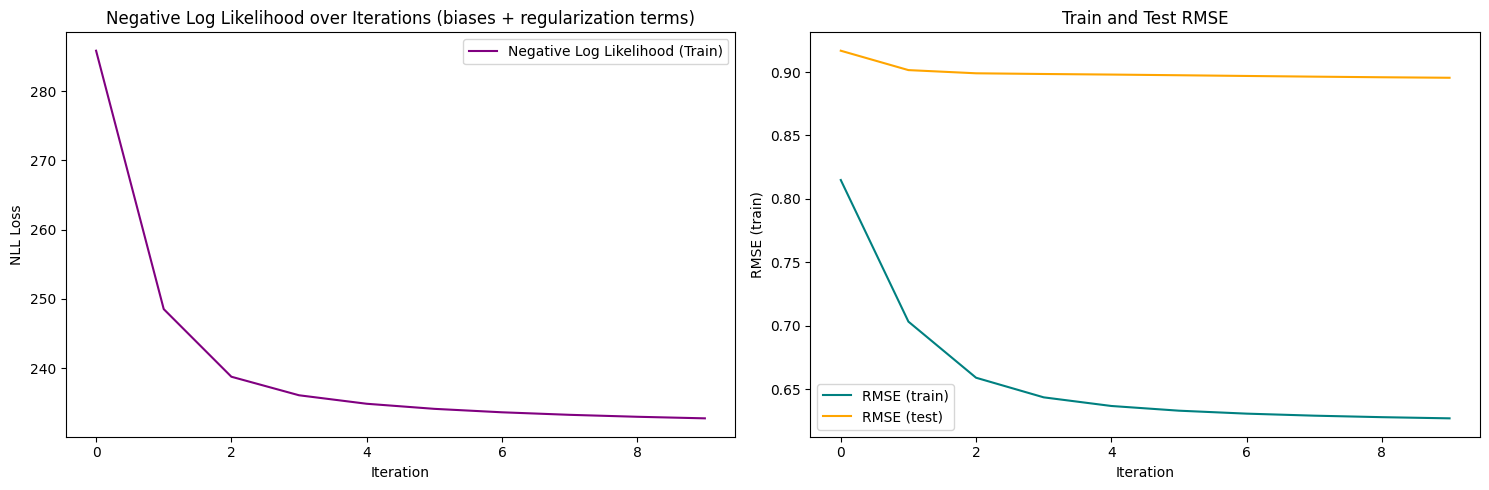

In [ ]:
M = len(data_by_user_train)
N = len(data_by_movie_train)
K = 12
user_biases = np.zeros((M))
movie_biases = np.zeros ((N))
U = np.random.normal(0,0.1, size=(M,K))
V = np.random.normal(0,0.1, size=(N,K))

lambd = 0.01
gamma = 0.01
tau = 0.1
n_iters = 10

mu = 0
num_ratings = 0
for m in range(M):
  for (n,r) in data_by_user_train[m]:
    mu += r
    num_ratings +=1
mu /= num_ratings

train_rmse_history = []
test_rmse_history = []
loss_history = []
neg_ll_history = []

for iter in range(n_iters):
  # Update user biases
  for m in range(M):
    bias = 0
    movie_counter = 0
    for (n,r) in data_by_user_train[m]:
      bias += lambd * (r - (mu + np.dot(U[m].T,V[n]) + movie_biases[n]))
      movie_counter += 1

    bias = bias / (lambd * movie_counter + gamma)
    user_biases[m] = bias

    # Update user vector
    A = tau * np.identity(K)
    b = np.zeros(K)
    for (n,r) in data_by_user_train[m]:
      A += lambd * np.outer(V[n], V[n])
      b += lambd * ((r - mu - user_biases[m] - movie_biases[n]) * V[n])

    U[m] = np.linalg.solve(A, b)

  # Update movie biases
  for n in range(N):
    bias = 0
    user_counter = 0
    for (m,r) in data_by_movie_train[n]:
      bias += lambd * (r - (mu + np.dot(U[m].T,V[n]) + user_biases[m]))
      user_counter += 1

    bias = bias / (lambd * user_counter + gamma)
    movie_biases[n] = bias

    # Update movie vector
    A = tau * np.identity(K)
    b = np.zeros(K)
    for (m,r) in data_by_movie_train[n]:
      A += lambd * np.outer(U[m], U[m])
      b += lambd * ((r - mu - user_biases[m] - movie_biases[n]) * U[m])

    V[n] = np.linalg.solve(A, b)


  # Training loss & RMSE
  squared_error = 0
  count = 0
  for m in range(M):
    for (n,r) in data_by_user_train[m]:
      pred = mu + user_biases[m] + movie_biases[n] + np.dot(U[m].T,V[n])
      squared_error += (r - pred) ** 2
      count += 1

  rmse_train = np.sqrt(squared_error / count)
  train_rmse_history.append(rmse_train)

  # Compute negative log likelihood on training data
  u_reg = np.sum(U ** 2)
  v_reg = np.sum(V ** 2)
  reg_bias = np.sum(user_biases ** 2) + np.sum(movie_biases ** 2)
  log_likelihood = -(lambd / 2) * squared_error - (tau/2)*(u_reg + v_reg) -(gamma / 2)*reg_bias
  neg_ll = -log_likelihood
  neg_ll_history.append(neg_ll)

  # Test RMSE
  squared_error_test = 0
  count_test = 0
  for m in range(M):
    for (n,r) in data_by_user_test[m]:
      pred = mu + user_biases[m] + movie_biases[n] + np.dot(U[m].T,V[n])
      squared_error_test += (r - pred) ** 2
      count_test += 1

  rmse_test = np.sqrt(squared_error_test / count_test)
  test_rmse_history.append(rmse_test)

  print(f"Iteration {iter+1}/{n_iters}: "
          f"Train RMSE = {rmse_train:.4f}, Test RMSE = {rmse_test:.4f}, "
          f"NLL Loss = {neg_ll:.2f}")


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Negative Log Likelihood
axes[0].plot(neg_ll_history, color='purple', label='Negative Log Likelihood (Train)')
axes[0].set_title("Negative Log Likelihood over Iterations (biases + regularization terms)")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("NLL Loss")
axes[0].legend()

# Plot 2
axes[1].plot(train_rmse_history, color='teal', label='RMSE (train)')
axes[1].plot(test_rmse_history, color='orange', label='RMSE (test)')
axes[1].set_title("Train and Test RMSE")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("RMSE (train)")
axes[1].legend()
plt.savefig('NLL_RMSE_biases_plus_reg.svg')


plt.tight_layout()
plt.show()


In [ ]:
print(f'Training RMSE corverges to : {train_rmse_history[-1]:.4f}')
print(f'Test RMSE corverges to : {test_rmse_history[-1]:.4f}')

Training RMSE corverges to : 0.5371
Test RMSE corverges to : 0.8808


# Practical 4

In [ ]:
path = '/content/drive/MyDrive/Colab Notebooks/ml_at_scale/ml-32m/ratings.csv'

# indexing map
user_to_index = {}
index_to_user = []
movie_to_index = {}
index_to_movie = []

data_by_user = []
data_by_movie = []

data_by_user_train = []
data_by_user_test = []
data_by_movie_train = []
data_by_movie_test = []

with open(path, 'r') as f:
  reader = csv.reader(f)
  next(reader) # exclude the row with headers
  for row in reader:
    user_id = int(row[0])
    movie_id = int(row[1])
    rating = float(row[2])

    if user_id not in user_to_index:
      m = len(index_to_user)
      user_to_index[user_id] = m
      index_to_user.append(user_id)
      data_by_user.append([])
      data_by_user_train.append([])
      data_by_user_test.append([])
    else:
      m = user_to_index[user_id]

    if movie_id not in movie_to_index:
      n = len(index_to_movie)
      movie_to_index[movie_id] = n
      index_to_movie.append(movie_id)
      data_by_movie.append([])
      data_by_movie_train.append([])
      data_by_movie_test.append([])
    else:
      n = movie_to_index[movie_id]

    data_by_user[m].append((n,rating))
    data_by_movie[n].append((m,rating))

    # Splitting into train and test sets

    cutoff = 0.1
    if rand.random() > cutoff:
      data_by_user_train[m].append((n,rating))
      data_by_movie_train[n].append((m,rating))
    else:
      data_by_user_test[m].append((n,rating))
      data_by_movie_test[n].append((m,rating))

# Optimisation Using Numba

In [ ]:
# Get ratings using list compression for users (train)
ratings_by_user = np.array([r
           for user_ratings in data_by_user_train
           for (n,r) in user_ratings])
movie_ids = np.array([n
           for user_ratings in data_by_user_train
           for (n,r) in user_ratings])
# Get number of users
user_counts = np.array([len(user) for user in data_by_user_train])

# Get start and end points for each user
user_splits = np.concatenate(([0], np.cumsum(user_counts)))


# Get ratings using list compression for movies (train)
ratings_by_movie = np.array([r
           for movie_ratings in data_by_movie_train
           for (m,r) in movie_ratings])
user_ids = np.array([m
           for movie_ratings in data_by_movie_train
           for (m,r) in movie_ratings])
# Get number of movies
movie_counts = np.array([len(movie) for movie in data_by_movie_train])

# Get start and end points for each movie
movie_splits = np.concatenate(([0], np.cumsum(movie_counts)))


# Get ratings using list compression for users (test)
ratings_by_user_test = np.array([r
           for user_ratings in data_by_user_test
           for (n,r) in user_ratings])
movie_ids_test = np.array([n
           for user_ratings in data_by_user_test
           for (n,r) in user_ratings])
# Get number of users
user_counts_test = np.array([len(user) for user in data_by_user_test])

# Get start and end points for each user
user_splits_test = np.concatenate(([0], np.cumsum(user_counts_test)))

In [ ]:
path = '/content/drive/MyDrive/Colab Notebooks/ml_at_scale/np_arrays'
np.savez(path, ratings_by_user=ratings_by_user, movie_ids=movie_ids,
         user_splits=user_splits, ratings_by_movie=ratings_by_movie,
         user_ids=user_ids, movie_splits=movie_splits,
         ratings_by_user_test=ratings_by_user_test,
         movie_ids_test=movie_ids_test, user_splits_test=user_splits_test)

In [3]:
# Load saved numpy arrays
path = '/content/drive/MyDrive/Colab Notebooks/ml_at_scale/np_arrays.npz'
loaded_nps = np.load(path)

ratings_by_user = loaded_nps['ratings_by_user']
movie_ids = loaded_nps['movie_ids']
user_splits = loaded_nps['user_splits']
ratings_by_movie = loaded_nps['ratings_by_movie']
user_ids= loaded_nps['user_ids']
movie_splits = loaded_nps['movie_splits']
ratings_by_user_test = loaded_nps['ratings_by_user_test']
movie_ids_test = loaded_nps['movie_ids_test']
user_splits_test = loaded_nps['user_splits_test']

In [5]:
from numba import njit

In [6]:
# Define functions for numba

# Function for updating users
@njit
def update_users_numba (
    M, K, lambd, gamma, tau, U, V, ratings_by_user,
    movie_ids, user_biases, movie_biases, user_splits
    ):
  for m in range(M):
    bias = 0
    start = user_splits[m]
    end = user_splits[m+1]
    movie_counter = end - start

    for i in range(start, end):
      r = ratings_by_user[i]
      n = movie_ids[i]
      bias += lambd * (
          r - ( np.dot(U[m],V[n]) + movie_biases[n])
          )

    user_biases[m] = bias / (lambd * movie_counter + gamma)

    A = tau * np.eye(K)
    b = np.zeros(K)

    for i in range(start, end):
      r = ratings_by_user[i]
      n = movie_ids[i]

      A += lambd * np.outer(V[n], V[n])
      b +=  (lambd * ((r -  user_biases[m] - movie_biases[n]) * V[n]))

    U[m] = np.linalg.solve(A, b)


# Function for updating movies
@njit
def update_movies_numba(N, K, lambd, gamma, tau, U, V, ratings_by_movie,
                        user_ids, movie_biases, user_biases, movie_splits):
  for n in range(N):
    bias = 0
    start = movie_splits[n]
    end = movie_splits[n+1]
    user_counter = end - start

    for i in range(start, end):
      r = ratings_by_movie[i]
      m = user_ids[i]
      bias += lambd * (r - ( np.dot(U[m],V[n]) + user_biases[m]))

    movie_biases[n] = bias / (lambd * user_counter + gamma)

    A = tau * np.eye(K)
    b = np.zeros(K)

    for i in range(start, end):
      r = ratings_by_movie[i]
      m = user_ids[i]

      A += lambd * np.outer(U[m], U[m])
      b +=  (lambd * ((r -  user_biases[m] - movie_biases[n]) * U[m]))

    V[n] = np.linalg.solve(A, b)

# Function for squared error
@njit
def squared_error_train_numba(M, U, V, user_splits, user_biases,
                              movie_biases, ratings_by_user, movie_ids):
  squared_error = 0

  for m in range(M):
    start = user_splits[m]
    end = user_splits[m+1]

    for i in range(start, end):
      r = ratings_by_user[i]
      n = movie_ids[i]

      pred =  user_biases[m] + movie_biases[n] + np.dot(U[m],V[n])
      squared_error += (r - pred) ** 2

  return squared_error

@njit
def squared_error_test_numba(M_test, U, V, ratings_by_user_test,
                             user_splits_test,movie_ids_test, user_biases,
                             movie_biases):
  squared_error_test = 0

  for m in range(M_test):
    start = user_splits_test[m]
    end = user_splits_test[m+1]

    for i in range(start, end):
      r = ratings_by_user_test[i]
      n = movie_ids_test[i]

      pred =  user_biases[m] + movie_biases[n] + np.dot(U[m],V[n])
      squared_error_test += (r - pred) ** 2

  return squared_error_test

## Using the training set for optimizing parameters

Iteration 1/10: Train RMSE = 0.7960, Test RMSE = 0.8980, NLL Loss = 91169.32 Time = 225.48s
Iteration 2/10: Train RMSE = 0.7196, Test RMSE = 0.8415, NLL Loss = 74487.32 Time = 218.53s
Iteration 3/10: Train RMSE = 0.6884, Test RMSE = 0.8156, NLL Loss = 68172.75 Time = 211.75s
Iteration 4/10: Train RMSE = 0.6742, Test RMSE = 0.8041, NLL Loss = 65377.38 Time = 210.13s
Iteration 5/10: Train RMSE = 0.6662, Test RMSE = 0.7982, NLL Loss = 63842.49 Time = 211.93s
Iteration 6/10: Train RMSE = 0.6613, Test RMSE = 0.7949, NLL Loss = 62901.74 Time = 216.95s
Iteration 7/10: Train RMSE = 0.6580, Test RMSE = 0.7931, NLL Loss = 62287.41 Time = 211.62s
Iteration 8/10: Train RMSE = 0.6558, Test RMSE = 0.7922, NLL Loss = 61866.22 Time = 211.44s
Iteration 9/10: Train RMSE = 0.6542, Test RMSE = 0.7919, NLL Loss = 61565.19 Time = 211.29s
Iteration 10/10: Train RMSE = 0.6530, Test RMSE = 0.7918, NLL Loss = 61342.28 Time = 212.14s


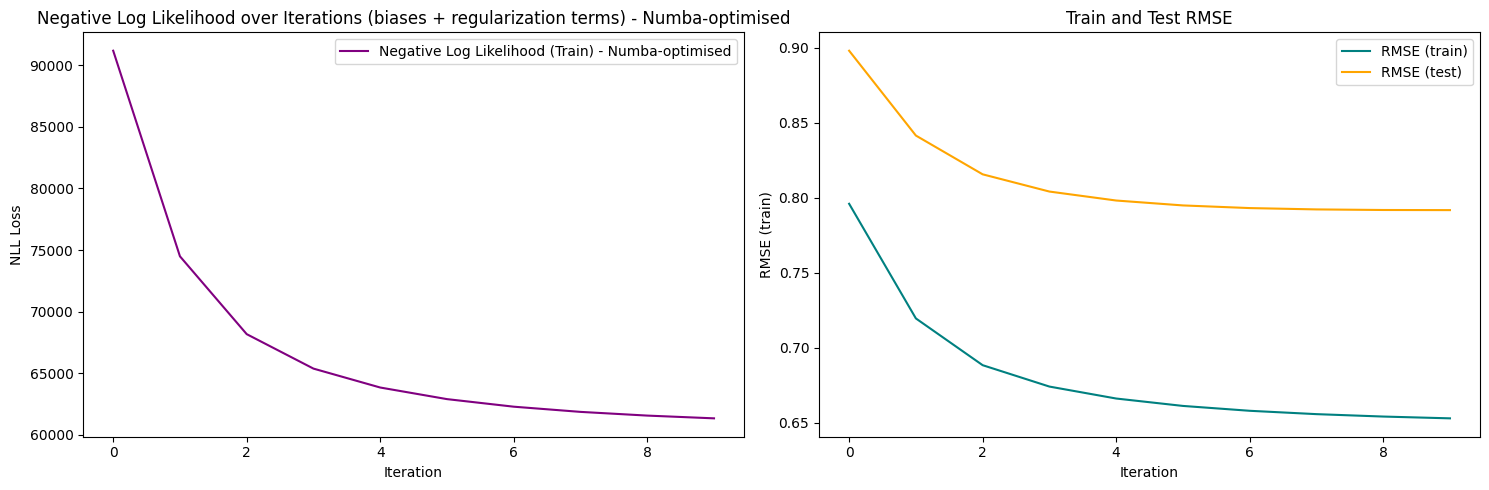

In [8]:
M = len(user_splits) - 1
M_test = len(user_splits) -1
N = len(movie_splits) - 1
K = 20

U = np.random.normal(0,0.1, size=(M,K))
V = np.random.normal(0,0.1, size=(N,K))
user_biases = np.zeros((M))
movie_biases = np.zeros ((N))

lambd = 0.01
gamma = 0.01
tau = 0.01
n_iters = 10

train_rmse_history = []
test_rmse_history = []
loss_history = []
neg_ll_history = []

for iter in range(n_iters):
  timer = time.time()
  # Update user biases and vectors
  update_users_numba (
    M, K, lambd, gamma, tau, U, V, ratings_by_user,
    movie_ids, user_biases, movie_biases, user_splits
    )

  # Update movie biases
  update_movies_numba(
      N, K, lambd, gamma, tau, U, V, ratings_by_movie,
      user_ids, movie_biases, user_biases, movie_splits
      )

  # Training loss & RMSE
  squared_error = squared_error_train_numba(
      M, U, V, user_splits, user_biases,
      movie_biases, ratings_by_user, movie_ids)

  rmse_train = np.sqrt(squared_error / len(ratings_by_user))
  train_rmse_history.append(rmse_train)

  # Compute negative log likelihood on training data
  u_reg = np.sum(np.dot(U.T,U))
  v_reg = np.sum(np.dot(V.T,V))
  reg_bias = np.sum(user_biases ** 2) + np.sum(movie_biases ** 2)
  log_likelihood = -(lambd / 2) * (squared_error - (tau/2)*(
      np.sum(U**2) + np.sum(V**2)) - (gamma / 2)*reg_bias)

  neg_ll = -log_likelihood
  neg_ll_history.append(neg_ll)

  # Test RMSE
  squared_error_test = squared_error_test_numba(
      M_test, U, V, ratings_by_user_test, user_splits_test,
      movie_ids_test, user_biases, movie_biases)

  rmse_test = np.sqrt(squared_error_test / len(ratings_by_user_test))
  test_rmse_history.append(rmse_test)

  time_taken = time.time() - timer

  print(f"Iteration {iter+1}/{n_iters}: "
          f"Train RMSE = {rmse_train:.4f}, Test RMSE = {rmse_test:.4f}, "
          f"NLL Loss = {neg_ll:.2f}",
          f"Time = {time_taken:.2f}s")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Negative Log Likelihood
axes[0].plot(neg_ll_history, color='purple', label='Negative Log Likelihood (Train) - Numba-optimised')
axes[0].set_title("Negative Log Likelihood over Iterations (biases + regularization terms) - Numba-optimised")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("NLL Loss")
axes[0].legend()

# Plot 2
axes[1].plot(train_rmse_history, color='teal', label='RMSE (train)')
axes[1].plot(test_rmse_history, color='orange', label='RMSE (test)')
axes[1].set_title("Train and Test RMSE")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("RMSE (train)")
axes[1].legend()
plt.savefig('NLL_RMSE_biases_plus_numba.svg')


plt.tight_layout()
plt.show()


In [9]:
path = '/content/drive/MyDrive/Colab Notebooks/ml_at_scale/vectors_biases.npz'
np.savez(path, U=U, V=V, user_biases=user_biases, movie_biases=movie_biases)